# ¿Cuánto se equivoca Euler hacia adelante y cuándo importa?

**Pregunta:** El motor avanza las ecuaciones SIR en pasos de un cuarto de día con el esquema más simple que existe. ¿Cuánto se alejan su pico y su tamaño final de los exactos en el caso epidémico, importa eso para los casos archivados, y cuánto costaría una respuesta mejor?

- **Nivel:** 2, El método en la práctica
- **Requisitos:** notebook 01 de este tema
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes escribir a mano un paso de Euler hacia adelante y encontrarlo en el primer paso del motor, medir el error del motor contra dos referencias exactas que no comparten código con él, leer el orden del esquema a partir de cómo el error baja con el paso, y juzgar para qué casos y qué cantidades un paso de un cuarto de día es suficientemente exacto. También ves cómo quitar la mayor parte del error sin un integrador mejor.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import peak_frac
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

## Método

Euler hacia adelante mueve un sistema $y' = f(y)$ siguiendo su tangente durante un paso $\Delta t$: $y_{k+1} = y_k + \Delta t\, f(y_k)$. Para el sistema SIR la tangente de un paso dice que $\beta S I \Delta t / N$ personas susceptibles se infectan y $\gamma I \Delta t$ infectadas se recuperan, que es todo lo que hace el motor (además recorta $S$ e $I$ en cero). El esquema es de primer orden: reducir $\Delta t$ a la mitad reduce a la mitad el error global (Hairer, Norsett y Wanner, 1993). Eso es una afirmación sobre un límite, y este notebook la mide en los pasos que se usan.

Para medir un error hace falta la respuesta exacta. Dos cantidades del sistema SIR la tienen en forma cerrada e independiente de cualquier integrador. El tamaño final resuelve $1 - z = (1 - i_0) e^{-R_0 z}$ (Kermack y McKendrick, 1927; Miller, 2012), que `final_size` de `pipeline/oracles.py` encuentra por iteración de punto fijo, y la fracción de infectados alcanza su máximo en $1 - (1 + \ln R_0) / R_0$ cuando la infección inicial tiende a cero, que `peak_frac` de `pipeline/model/baseline.py` evalúa. El pico analítico ignora a las primeras 50 personas infectadas, así que se desvía una fracción de uno por ciento; hay que tenerlo presente al leer los errores del pico.

Primero un paso a mano, sobre el caso epidémico con $\Delta t = 0{,}25$ días. Las nuevas infecciones son $\beta (N - I_0) I_0 \Delta t / N$ y las nuevas recuperaciones $\gamma I_0 \Delta t$. La celda calcula los tres compartimentos después de un paso con aritmética simple y los imprime junto al primer paso de `simulate`. Si la descripción del esquema es correcta, las dos líneas coinciden.

In [2]:
# un paso de Euler hacia adelante a mano en el caso epidémico, junto al primer paso del motor
p = params_of("EX02_epidemic")
dt = 0.25
new_infections = p.beta / p.N * (p.N - p.I0) * p.I0 * dt
new_recoveries = p.gamma * p.I0 * dt
by_hand = [p.N - p.I0 - new_infections, p.I0 + new_infections - new_recoveries, new_recoveries]
engine = simulate(p, dt)
print("a mano     ", [round(v, 3) for v in by_hand])
print("motor    ", [round(v[1], 3) for v in (engine.S, engine.I, engine.R)])

a mano      [99943.128, 54.372, 2.5]
motor     [99943.128, 54.372, 2.5]


Las dos líneas son iguales hasta tres decimales: el motor es el esquema de los textos y nada más. Ahora la pregunta es qué tan lejos está ese esquema de la verdad. La celda siguiente corre el motor sobre el caso epidémico con cinco pasos, desde un día entero hasta un dieciseisavo de día, y compara cada corrida con las dos referencias exactas. Imprime el número de pasos de cada corrida, que es el costo, junto a la tasa de ataque y el pico que produjo.

In [3]:
# el motor con cinco pasos en el caso epidémico, frente al tamaño final exacto y al pico analítico
p = params_of("EX02_epidemic")
steps = [1.0, 0.5, 0.25, 0.125, 0.0625]
exact_attack = final_size(p.beta / p.gamma, p.I0 / p.N)
exact_peak = peak_frac(p.beta / p.gamma) * p.N
attack_error = []
peak_error = []
for dt in steps:
    r = simulate(p, dt)
    attack_error.append(r.attack_rate - exact_attack)
    peak_error.append(r.peak_I / exact_peak - 1)
    print(f"dt = {dt:6.4f}  {len(r.t) - 1:5d} pasos  tasa de ataque {r.attack_rate:.6f}  pico {r.peak_I:7.0f}")
print(f"exacto: tasa de ataque {exact_attack:.6f}, pico {exact_peak:.0f}")

dt = 1.0000    160 pasos  tasa de ataque 0.933717  pico   28845
dt = 0.5000    320 pasos  tasa de ataque 0.926912  pico   27836
dt = 0.2500    640 pasos  tasa de ataque 0.923654  pico   27345
dt = 0.1250   1280 pasos  tasa de ataque 0.922060  pico   27107
dt = 0.0625   2560 pasos  tasa de ataque 0.921271  pico   26988
exacto: tasa de ataque 0.920487, pico 26851


La tasa de ataque baja desde 0,933717 con un paso de un día hacia la exacta 0,920487 y no llega; el pico baja de 28845 hacia 26851 de la misma manera, y el trabajo crece en proporción, de 160 a 2560 pasos. La celda siguiente dibuja ambos errores contra el paso en ejes logarítmicos, con una recta de pendiente uno para comparar. Un esquema de primer orden debe correr paralelo a esa recta.

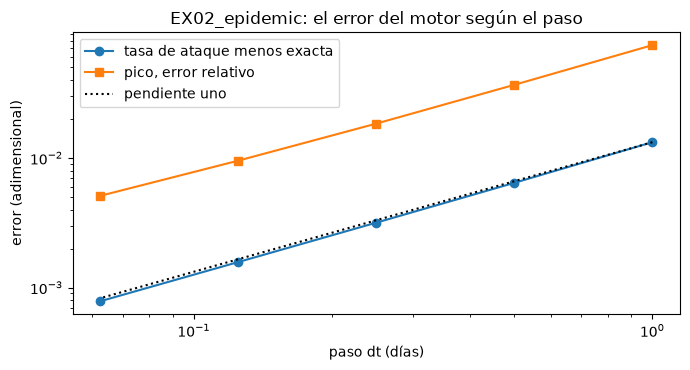

In [4]:
# dibuja los dos errores contra el paso en ejes log, con una recta de pendiente uno para comparar
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(steps, np.abs(attack_error), "o-", label="tasa de ataque menos exacta")
ax.loglog(steps, np.abs(peak_error), "s-", label="pico, error relativo")
ax.loglog(steps, np.array(steps) * attack_error[0] / steps[0], "k:", label="pendiente uno")
ax.set_xlabel("paso dt (días)")
ax.set_ylabel("error (adimensional)")
ax.set_title("EX02_epidemic: el error del motor según el paso")
ax.legend()
fig.tight_layout()
plt.show()

En ejes logarítmicos ambos errores caen sobre rectas paralelas a la recta punteada de pendiente uno: cada vez que el paso se reduce a la mitad, el error de la tasa de ataque y el del pico también se reducen a la mitad, que es la firma de un esquema de primer orden. Con el paso propio del motor, 0,25 días, la tasa de ataque queda alta en cerca de 0,003 y el pico en 1,8 por ciento, de modo que el pico es el más sensible de los dos. La figura no dice en qué parte del curso se comete el error, que es lo que muestra la corrida de referencia más abajo.

¿Cuánto costaría llevar el pico a menos de una décima de por ciento? Si el error sigue bajando en proporción al paso, el paso debe bajar en el mismo factor. La celda extrapola desde el error con 0,25 días e imprime el paso que eso implica y el trabajo que multiplica.

In [5]:
# el paso que necesitaría un pico a menos de 0,1 por ciento, si el error sigue bajando con el paso
per_day = peak_error[2] / steps[2]
needed = 0.001 / per_day
print(f"ahora: dt = {steps[2]}, error relativo del pico {peak_error[2]:+.4f}, {p.days / steps[2]:.0f} pasos")
steps_needed = p.days / needed
work = steps_needed / (p.days / steps[2])
print(f"necesario: dt = {needed:.4f}, {steps_needed:.0f} pasos, {work:.0f} veces el trabajo")

ahora: dt = 0.25, error relativo del pico +0.0184, 640 pasos
necesario: dt = 0.0136, 11783 pasos, 18 veces el trabajo


Un pico a menos de 0,1 por ciento necesita un paso de unos 0,0136 días y 11783 pasos, 18 veces el trabajo del valor por defecto del motor. Eso es barato aquí, donde una corrida toma milisegundos, y no lo sería para un modelo que cuesta minutos por corrida. El pico analítico no puede mostrar de dónde viene el error, así que la celda siguiente construye un curso de referencia con un paso 32 veces más fino que el del motor y lo resta de los cursos con paso de un día y de un cuarto de día, punto por punto. Para alinear las mallas la celda toma uno de cada 32 puntos de la corrida fina para el curso de un cuarto de día y uno de cada 128 para el de un día.

In [6]:
# un curso de referencia con un paso 32 veces más fino que el del motor, y el error de dos cursos más gruesos
reference = simulate(p, 1 / 128)
reference_i = np.array(reference.I)
errors = {}
for dt in (1.0, 0.25):
    course = simulate(p, dt)
    errors[dt] = (np.array(course.I) - reference_i[:: round(dt * 128)]) / p.N
    worst = int(errors[dt].argmax())
    print(f"dt = {dt:4.2f}  máximo {errors[dt][worst]:+.4f} el día {course.t[worst]:.2f}", end="  ")
    print(f"mínimo {errors[dt].min():+.4f}")

dt = 1.00  máximo +0.0660 el día 29.00  mínimo -0.0749
dt = 0.25  máximo +0.0154 el día 27.75  mínimo -0.0195


La celda siguiente dibuja el error de la curva de infectados a lo largo del horizonte, como parte de la población, para los dos cursos.

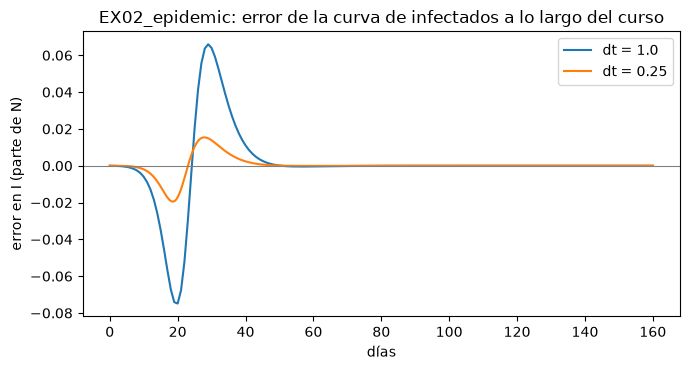

In [7]:
# dibuja el error de la curva de infectados en el horizonte, como parte de la población
fig, ax = plt.subplots(figsize=(7, 3.8))
for dt, err in errors.items():
    ax.plot(np.arange(len(err)) * dt, err, label=f"dt = {dt}")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("días")
ax.set_ylabel("error en I (parte de N)")
ax.set_title("EX02_epidemic: error de la curva de infectados a lo largo del curso")
ax.legend()
fig.tight_layout()
plt.show()

El error de la curva de infectados tiene una forma con signo: negativo en la subida y positivo justo después del pico, porque la joroba de Euler llega un poco tarde y un poco alta. Con el paso del motor el error máximo es 0,0154 de la población, el día 27,75, frente a 0,0660 con un paso de un día, cuatro veces más grande para un paso cuatro veces más grande. El error es mayor donde la curva es más empinada, como debe ocurrir con un esquema que sigue la tangente. La figura no contiene los otros cuatro casos; la celda siguiente sí.

¿Cuándo importa un paso de un cuarto de día? Depende del caso y de la cantidad. La celda siguiente corre cada caso con personas infectadas con el paso del motor y con el paso fino, e imprime cuánto se mueven el pico del motor, el día del pico y la tasa de ataque. La referencia aquí es la corrida fina y no las fórmulas analíticas, por lo que los números difieren un poco de los anteriores: la corrida fina tiene su propio error, cerca de 0,06 por ciento en el pico.

In [8]:
# el error del paso propio del motor en cada caso con infectados, frente a la referencia más fina
print(f"{'caso':18s} {'err. pico':>10s} {'desfase día':>12s} {'err. tasa':>12s}")
for case_id in CASES:
    q = params_of(case_id)
    if q.I0 == 0:
        continue
    fine = simulate(q, 1 / 128)
    own = simulate(q)
    d_peak = own.peak_I / fine.peak_I - 1
    d_day = own.t_peak - fine.t_peak
    d_attack = own.attack_rate - fine.attack_rate
    print(f"{case_id:18s} {d_peak:+10.4f} {d_day:+12.2f} {d_attack:+12.5f}")

caso                err. pico  desfase día    err. tasa
EX01_subcritical      +0.0000        +0.00     +0.00000
EX02_epidemic         +0.0172        +0.79     +0.00307
EX03_fast_burn        +0.0322        +0.53     +0.00070
EX04_slow_spread      +0.0038        +0.32     +0.00051


La combustión rápida tiene el mayor error de pico, 3,2 por ciento, y la propagación lenta el menor, 0,4 por ciento: mientras más rápida la dinámica, más del curso se salta un paso de un cuarto de día. El pico llega entre 0,3 y 0,8 días tarde en los casos con brote. La tasa de ataque queda alta en 0,003 como máximo, y el caso subcrítico no tiene error alguno porque en él no pasa nada. Frente a las bandas que declaran los casos del ejemplo (`expect` en `pipeline/cases/example_case.py`), una tasa de ataque entre 0,90 y 0,95 para el caso epidémico, el paso es inofensivo; para una decisión que dimensiona capacidad sobre el pico con un margen de pocos por ciento, no lo es.

Por último, una manera de mejorar la respuesta sin tocar el integrador. Si el error es proporcional al paso, tres corridas con $\Delta t$, $\Delta t / 2$ y $\Delta t / 4$ revelan el orden por el cociente de sus diferencias, y las dos últimas extrapolan a un paso nulo: $2 x_{\Delta t/4} - x_{\Delta t/2}$ (extrapolación de Richardson, véase Hairer, Norsett y Wanner, 1993). La celda lo hace con la tasa de ataque, que el tamaño final exacto permite juzgar.

In [9]:
# estima el orden del esquema con tres corridas con dt, dt / 2 y dt / 4, sin necesitar la respuesta exacta
attack = [simulate(p, dt).attack_rate for dt in (0.5, 0.25, 0.125)]
order = np.log2((attack[0] - attack[1]) / (attack[1] - attack[2]))
extrapolated = 2 * attack[2] - attack[1]
print(f"orden estimado: {order:.2f}")
print(f"corrida más fina {attack[2]:.6f}, extrapolada {extrapolated:.6f}, exacto {exact_attack:.6f}")

orden estimado: 1.03
corrida más fina 0.922060, extrapolada 0.920465, exacto 0.920487


## Resultados

**Respuesta:** Con el paso de un cuarto de día del motor, el caso epidémico termina con una tasa de ataque de 0,923654 frente a la exacta de 0,920487, y un pico de 27345 personas frente a las 26851 analíticas, 1,8 por ciento más alto. Los dos errores se reducen a la mitad cuando el paso se reduce a la mitad: el orden estimado es 1,03. Para los casos archivados el error del pico va de 0,4 por ciento en la propagación lenta a 3,2 por ciento en la combustión rápida, el pico llega hasta 0,79 días tarde, y la tasa de ataque se desvía 0,003 como máximo. Un pico a menos de 0,1 por ciento necesitaría 11783 pasos, 18 veces el trabajo, pero extrapolar desde las corridas con 0,5, 0,25 y 0,125 días da 0,920465 para la tasa de ataque, a menos de 0,00003 del valor exacto, al precio de dos corridas baratas más.

Así, un paso de un cuarto de día es suficientemente exacto para el tamaño final y para fechar el pico con un día de tolerancia, y no para dimensionar el pico mismo cuando el margen es de pocos por ciento. Lo que el notebook no muestra es el error de un esquema de orden mayor, que es el tema del notebook 03, ni el error con otros parámetros que los cinco archivados; la combustión rápida sugiere que crece con $\beta$.

## Resumen

- El paso del motor es el paso de Euler hacia adelante: el cálculo a mano coincide con su primer paso.
- Su error es de primer orden: reducir el paso a la mitad reduce a la mitad el error de la tasa de ataque y del pico (orden 1,03).
- Con el paso por defecto de un cuarto de día el pico queda 1,8 por ciento alto en el caso epidémico y hasta 3,2 por ciento en la combustión rápida; la tasa de ataque se desvía 0,003 como máximo.
- La extrapolación de Richardson con tres corridas baratas quita la mayor parte del error de la tasa de ataque.
- Siguiente: los mismos casos frente a un resolvedor de orden mayor, en el notebook 03 de este tema.

## Referencias

- Hairer, E., Norsett, S. P. y Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- Kermack, W. O. y McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor, el oráculo y la línea base de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`, `pipeline/model/baseline.py`).